# Mandatory Assignment 3: ML in Production Environment - Preliminary Notebook
#### Group: 04
Group members: Brage Blomkvist, Patrick Rafael Jemieljanczyk & William Bjørling Nilsen

This notebook is for the work done on the models before they would enter a production environment such as feature importance analysis and threshold tuning. It is based on the notebook named Ensemble Models & Artificial Neural Networks from the 2nd mandatory assignment. The models used are from an early version of the second assignment. After consulting with the main lecturer in this course, this was deemed perfectly adequate for this assignment. Since the models are not created in this assignment, notebook cells which are only needed for training models are removed. Additionally, cells from the 2nd mandatory assignment are altered or removed to make this notebook smaller and more relevant to the 3rd assignment. Please see the previous assignment for more details.

The notebook is split into two main parts. Part A is highly based on the previous assignment and can be mostly overlooked. Part B is for the new material introduced in this assignment.

In [69]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('default')
import seaborn as sns

# Save and load GridSearchCV objects:
from os import path as pth
import joblib


#Sklearn
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, TargetEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, make_scorer, confusion_matrix, \
    ConfusionMatrixDisplay, roc_curve, auc, PrecisionRecallDisplay, fbeta_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, TunedThresholdClassifierCV

# Part A: Processing and Fetching Models

### Dataset Used
The dataset used is the same as the 2nd assignment. The dataset includes a set of daily weather observations from Australia. It is available on Kaggle through the site-publisher Joe Young (https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package/data).





In [3]:
# Read the dataset
dataset_AUS = pd.read_csv('Dataset/weatherAUS.csv')
# Uses existing column names baked into csv file.

# Constant for target value
TARGET = "RainTomorrow"

# Show the first 5 rows to validate that the data import has been successful
dataset_AUS.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


## Data Processing


### Outlier removal

In [4]:
#Outlier removal based on EDA
dataset_AUS = dataset_AUS.loc[(dataset_AUS['Rainfall'] < 350)
                                        & (dataset_AUS['Evaporation'] < 100)
                                        & (dataset_AUS['WindSpeed9am'] < 100)]

### Nested Cross Validation Preparation


In [5]:
# Creating a temporary dataset
dataset_AUS_temp = dataset_AUS.copy()

# Removing rows where RainTomorrow is missing
dataset_AUS_temp = dataset_AUS_temp.dropna(subset=['RainTomorrow'])

#Converting the Date feature to datetime for sorting
dataset_AUS_temp['Date'] = pd.to_datetime(dataset_AUS_temp['Date'])

#Sorting the dataset chronologically
dataset_AUS_temp = dataset_AUS_temp.sort_values(by=['Date'])

# Temporary separating into targets and features
targets = dataset_AUS_temp['RainTomorrow'].map({'Yes' : 1, 'No' : 0})
features = dataset_AUS_temp.drop(columns=['RainTomorrow'])

# Select numerical columns
numerical_features = features.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Select categorical columns
categorical_features = features.select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist()

## Pipelines
to do:
   - Make the processor able to remove certain columns. Can then eventually see which models perform better

   - Can make it an option to delete the feature day_of_year

   - Make an option in the pipeline which can delete the following columns: temp3am, temp9am, year and pressure3pm


In [6]:
# Putting the features which need to be encoded into variables as a list. To be used by pipelines to encode
location_features = ['Location']

rain_today_features = ['RainToday']

wind_features = [
    'WindGustDir',
    'WindDir9am',
    'WindDir3pm'
]

date_features = ['Date']

In [7]:
# Cyclical encoder function
def cyclic_encoder(series, period):
    sin = np.sin(2 * np.pi * series / period)
    cos = np.cos(2 * np.pi * series / period)

    return sin, cos


In [8]:
wind_map = {
    'N': 1, 'NNE': 2, 'NE': 3, 'ENE': 4,
    'E': 5, 'ESE': 6, 'SE': 7, 'SSE': 8,
    'S': 9, 'SSW': 10, 'SW': 11, 'WSW': 12,
    'W': 13, 'WNW': 14, 'NW': 15, 'NNW': 16
}

WIND_DIRECTIONS = 16
MONTH_PERIOD = 12

In [9]:
def encode_rain_today(rain_today_dataframe):
    return rain_today_dataframe.replace({'No': 0, 'Yes': 1}).astype(float)

# encode_wind() function needs for-loop because there are three features which need to be encoded by this function.
def encode_wind(wind_data_frame):
    result = pd.DataFrame()

    for column in wind_data_frame.columns:

        wind_numbers = wind_data_frame[column].map(wind_map).astype(float)

        sin, cos = cyclic_encoder(wind_numbers, WIND_DIRECTIONS)
        result[column + '_Sine'], result[column + '_Cosine'] = sin, cos

    return result

# encode_date() function doesn't need a for loop because there is only a single feature with the dates provided.
def encode_date(dataframe):
    result = pd.DataFrame()

    date = pd.to_datetime(dataframe['Date'])
    year = date.dt.year
    month = date.dt.month
    day = date.dt.day_of_year

    is_leap_year = ((year % 4 == 0) & (year % 100 != 0)) | (year % 400 == 0)
    days_in_year = np.select([is_leap_year], [366], default = 365)

    result['Month_Sine'], result['Month_Cosine'] = cyclic_encoder(month, MONTH_PERIOD)

    result['Day_Sine'], result['Day_Cosine'] = cyclic_encoder(day, days_in_year)

    result['Year'] = year

    return result


### Encoding pipelines

In [10]:
# Numerical pipeline
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Location pipeline
location_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', TargetEncoder(target_type='binary',))
])

rain_today_pipeline = Pipeline([
    ('encoder', FunctionTransformer(encode_rain_today)),
    ('imputer', SimpleImputer(strategy='most_frequent'))
])

# Wind pipeline
wind_cyclical_pipeline = Pipeline([
    ('encoder', FunctionTransformer(encode_wind)),
    ('imputer', SimpleImputer(strategy='constant'))
])

# Date pipeline
date_cyclical_pipeline = Pipeline([
    ('encoder', FunctionTransformer(encode_date)),
    ('imputer', SimpleImputer(strategy='median'))
])



### Preprocessor

In [11]:
# Preprocessor
preprocessor = ColumnTransformer([
    ('numerical', numerical_pipeline, numerical_features),
    ('location', location_pipeline, location_features),
    ('rain_today', rain_today_pipeline, rain_today_features),
    ('wind', wind_cyclical_pipeline, wind_features),
    ('date', date_cyclical_pipeline, date_features)
])

## Function for Model Training


In [14]:
# Function for saving and loading GridSearchCV objects
def getModelGrid(pipeline, params,features_train, targets_train, inner_splits, path="Models/default_model.pkl", overwrite_existing=0, n_jobs = 1, score = "recall"):
    # Fit model if either the flag for a new model is active or no model is found. If the flag is false and a model is found, the old model is loaded.
    if not pth.isfile(path) or overwrite_existing:
        grid = GridSearchCV(estimator=pipeline, param_grid=params, cv=inner_splits, n_jobs=n_jobs, scoring=score)
        grid.fit(features_train, targets_train)
        joblib.dump(grid, path)
        print(f"Grid saved at: {path}")
    else:
        grid = joblib.load(path)
        print(f"Grid loaded from: {path}")
    return grid, pd.DataFrame(grid.cv_results_)

## Nested Cross Validation

In [15]:
def nested_cross_validation(
        model_pipeline,
        param_grid,
        features=features,
        targets=targets,
        outer_split=5,
        inner_split=3,
        gap = 1,
        n_jobs = 1,
        score='recall',
        save_path='Models',
        model_name = 'default',
        overwrite_existing = 0
):

    dates = pd.Series(dataset_AUS_temp['Date'])
    unique_dates = pd.Series(dataset_AUS_temp['Date'].unique())
    #Creating outer and inner CV loop
    outer_cv = TimeSeriesSplit(
        n_splits=outer_split,
        gap=gap
    )
    inner_cv = TimeSeriesSplit(
        n_splits=inner_split,
        gap=gap
        )
    assert dates.index.equals(features.index) and dates.index.equals(targets.index)
    #Storing results
    outer_results = []
    best_models = []
    best_params = []
    grid_results = []

    #Outer CV iterates on unique dates so that there won't be any mixing of testing and validation on the same day
    for fold, (trainCvIndices, testIndices) in enumerate(outer_cv.split(unique_dates), 1):

        #Saves the training+validation and test dates
        outer_train_cv_dates = unique_dates.iloc[trainCvIndices]
        outer_test_dates = unique_dates.iloc[testIndices]

        #Checking which rows belong to Training+Validation and Testing
        outer_train_cv_rows = dates.isin(outer_train_cv_dates)
        outer_test_rows = dates.isin(outer_test_dates)

        #Distributing the features and targets for CV and testing
        xTrainCv = features.loc[outer_train_cv_rows]
        yTrainCv = targets.loc[outer_train_cv_rows]

        xTest = features.loc[outer_test_rows]
        yTest = targets.loc[outer_test_rows]

        #Inner CV dates
        inner_train_cv_rows = dates.loc[outer_train_cv_rows]

        inner_splits = []
        #Inner CV splits the outer CV training dates into training and validation groups
        for inner_train_index, inner_val_index in inner_cv.split(outer_train_cv_dates):
            inner_train_dates = outer_train_cv_dates.iloc[inner_train_index]
            inner_val_dates = outer_train_cv_dates[inner_val_index]

            #Makes lists of indices that are to be included in the training and validation splits for GridSearchCV
            inner_train_rows = np.flatnonzero(
                inner_train_cv_rows.isin(
                    inner_train_dates).to_numpy()
            )
            inner_val_rows = np.flatnonzero(
                inner_train_cv_rows.isin(
                    inner_val_dates).to_numpy()
            )

            inner_splits.append((inner_train_rows, inner_val_rows))

        grid, grid_result = getModelGrid(
            pipeline=model_pipeline,
            params=param_grid,
            features_train=xTrainCv,
            targets_train=yTrainCv,
            inner_splits=inner_splits,
            path=f"{save_path}/{model_name}_fold_{fold}.pkl",
            overwrite_existing=overwrite_existing,
            n_jobs=n_jobs,
            score=score,
        )

        grid_results.append(grid_result)

        print(
                f"Fold {fold}: "
                f"Training: {outer_train_cv_dates.min()} to {outer_train_cv_dates.max()}, "
                f"Testing: {outer_test_dates.min()} to {outer_test_dates.max()}"
        )

        #Finding the best performing models and their parameters
        predictions = grid.best_estimator_.predict(xTest)

        #Evaluation
        results = {
            "Fold": fold,
            "Accuracy": accuracy_score(yTest, predictions),
            "Precision": precision_score(yTest, predictions, zero_division=0),
            "Recall": recall_score(yTest, predictions, zero_division=0),
            "f1": f1_score(yTest, predictions, zero_division=0),
        }

        outer_results.append(results)
        best_models.append(grid.best_estimator_)
        best_params.append(grid.best_params_)

    return outer_results, best_models, best_params, grid_results

In [17]:
def printResults(results_list):
    for results in results_list:
        for key, value in results.items():
            print(f"{key}: {value:.3f}")

## Evaluation & Comparison
When doing the evaluation of the models, multiple metrics are used. However, both here and throughout the notebook, the metric recall is regarded as the most important. This means most models are primarily tuned towards this metric. Recall is the true positive rate divided by the sum of the true positive rate and false negative rate. Overall, this means that recall is a metric which shows how many of the positive values where correctly predicted as positive by the model. This is the preferred metric for this problem as the basis for the problem is that an action taken tomorrow requires there to be no rain. It could, and that is the way it is interpreted in this notebook, therefore be better to not plan the action the day before rather than missing an opportunity to do the action. In summary, a false positive is generally considered better than a false negative in the evaluation.

In [50]:
# Start by fetching the models from their saved location.
# Manually load saved models:

path = "Models/rf_pipe2_fold_1.pkl"
rf_grid = joblib.load(path)

path = "Models/gb_pipe_fold_1.pkl"
gb_grid = joblib.load(path)


path = "Models/nnMLP_pipe_fold_1.pkl"
nnMLP_grid = joblib.load(path)



C:\Users\wilbn\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\wilbn\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\wilbn\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimato

In [51]:
# Dictionary of models to use in evaluation
models = {"Random Forest": rf_grid,
          "Gradient Boosting": gb_grid,
          "Multilayer Perceptron": nnMLP_grid}

Note: By fetching the models in this simple way, only one fold's model is represented in the evaluation. This means that the evaluation does not cover all the models created with nested cross validation. The evaluation thereby suffers from the same problem that using random states does.

For consistency, the first fold is always selected.

In [52]:
# Function for returning average results between folds.
# After other changes in the notebook, this is only used once.
def getAverageMetrics(results):
    # Initialize lists of metric values for current fold
    accuracy_list = []
    precision_list = []
    recall_list = []
    f1_list = []

    # Partition every fold's metrics into each metric.
    for fold in results:
        accuracy_list.append(fold["Accuracy"])
        precision_list.append(fold["Precision"])
        recall_list.append(fold["Recall"])
        f1_list.append(fold["f1"])

        # Average each metric across folds.
    accuracy = np.average(accuracy_list)
    precision = np.average(precision_list)
    recall = np.average(recall_list)
    f1 = np.average(f1_list)

    return accuracy, precision, recall, f1

#### Combined Results Table
A table showing the combined results of the models is provided. The table uses the result returned from the nested_cross_validation function. This leads to the deprecated decision trees being excluded from the table. On the contrary, using these values means that this table is the only evaluation technique which takes advantage of the cross validation, as it uses the average values for the metrics between each fold.

In [53]:
# The table is based on the last assignment's result table.

# Function which takes in a model name, its result and the table to append to.
def metrics_table_append(model_name, results, table):

    # Fetch average results between folds for the given model's results.
    accuracy, precision, recall, f1 = getAverageMetrics(results)

    row={
        'Model': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1': f1,
    }

    # Returns the dataframe passed in through the table parameter as a dataframe with an additional row
    # of metrics for one model.
    return pd.concat([table, pd.DataFrame([row])], ignore_index=True)


In [54]:
list(models.keys())

['Random Forest', 'Gradient Boosting', 'Multilayer Perceptron']

In [55]:
# Result table removed since it uses models not loaded (all folds)
# result_table = pd.DataFrame()
model_names = list(models.keys())

# result_table = metrics_table_append(model_names[3], rf_scores, result_table)
# result_table = metrics_table_append(model_names[5], gb_outer_new_results, result_table)
# result_table = metrics_table_append(model_names[7], mlp_scores, result_table)
# result_table.round(3)

Judging by recall the Linear Classifier is far ahead of the other models. On the other hand, it does worse in every other metric than most of the models. In particular, the precision metric is only 0.563. This indicates the model is very quick to predict rain the following day. The rest of the models are closer together, with the AdaBoost, Gradient Boosting and Keras Neural Network models all having an average recall from 0.542 to 0.582. The MLP neural network fares worst out of the tested models in regard to the recall metric with only a score of 0.467. The accuracy metric is almost the same list as the recall list, but flipped. At the top is Random Forest, with the AdaBoost models lagging behind at only 0.741. This indicates how the models are balancing each metric. The best example is actually the new Linear Classifier models which are not shown in the table, but would take a huge hit in accuracy to be clearly ahead in the recall metric. While recall is considered to be the most important metric for this task, it is important to not get to carried away when choosing the best model. The risk of using the model with the highest recall is that the usefulness of the model decreases largely. For this dataset, this means that an action which requires no rain tomorrow will have many missed opportunities of happening since the model often wrongfully predicts rain the following day.

The F1 score is often considered a good metric to use if neither precision nor recall is more important. The F1 score is the harmonic mean of recall and precision which means it considers both equally when scoring the models. The old Linear Classifier and Random Forest models scores best in this parameter, but there is less than 0.1 difference between Random Forest and the worst models in regard to F1 score. The worst models when using the generic F1-score is Adaptive Boosting at only 0.505. It has less than 0.5 precision with only 0.582 recall to make up for it.

Note: The new Linear Classifier was first used. It had an increased recall, but would almost always predict rain, making the model of little use.

### Confusion Matrices & Additional Plots

#### Confusion Matrices
Confusion Matrices are used to evaluate the models' performance based on how many of the predictions corresponds to the true value. This is done with an nxn matrix where n is the number of possible classes.

In [56]:
# A function for plotting a confusion matrix for a model on the entire dataset.
def show_confusion(model, ax, title):
    predictions = model.predict(features)
    confusion = confusion_matrix(targets, predictions)
    display = ConfusionMatrixDisplay(confusion)
    display.plot(ax=ax)
    ax.set_title(title)

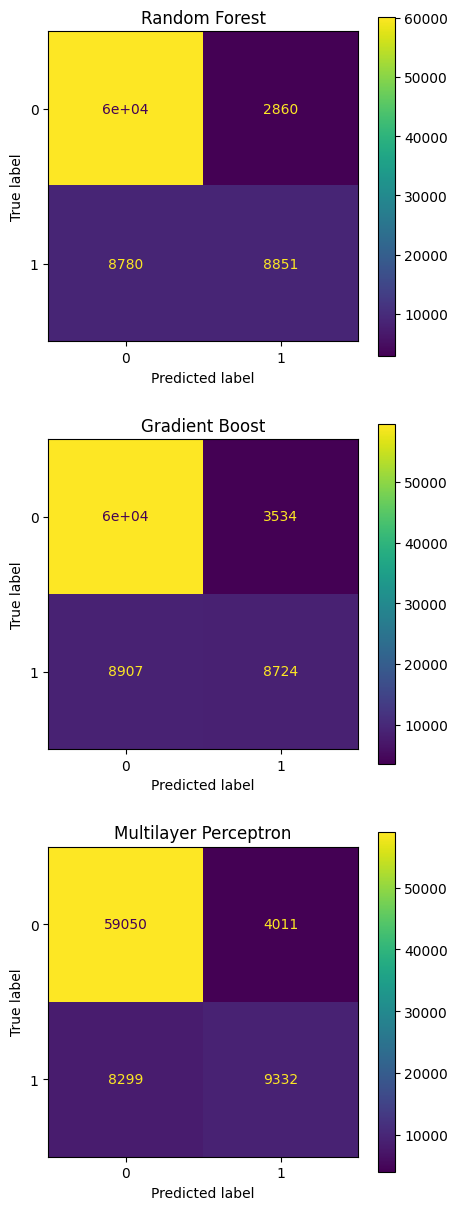

In [66]:
fig, ax = plt.subplots(3,1, figsize=(5,15))

show_confusion(rf_grid, ax[0], "Random Forest")
show_confusion(gb_grid, ax[1], "Gradient Boost")
show_confusion(nnMLP_grid, ax[2], "Multilayer Perceptron")

The benefit of using confusion matrices is lower when only having a binary classification problem. It does instead show in concrete numbers which models are best at predicting positive labels vs the models that are better at predicting negative labels. This follows a pattern from the previously seen metrics. The models which have higher recall will be better at predicting positive labels at the cost of failing to predict more false labels. The model with the most correctly predicted false labels is the Keras Neural Network, with the Linear Classifier and Random Forest following closely. Since there are so many true negative labels in comparison to true positives, the difference between the models in correctly predicted false labels is relatively low in comparison. There is a larger gap between the comparative difference between the models' correctly predicted true labels. The tuned decision tree leads in this metric. There are a row of models which are close with around 9000 correctly predicted true labels. The only models which lag significantly behind this number is the Linear Classifier with only 6563 and the Keras Neural Network with 7880 true positive labels. This metric, or rather the inverse, is the most important implied by the problem. Written with the domain in mind, the true positive values represent days where the next day has rain. The most important cell to look at in the confusion matrices is therefore the bottom left. The desire is to have the least amount of predicted negative labels when they are in truth positive. Additionally it is important to strike a balance between this metric and the accurately predicted false labels so that the model is actually useful.

#### Receiver Operating Characteristic
This metric is used for an overall comparison between different models. It works best for binary classification problems and shows the values of true positive rate against the false positive rate. Since the problem implies that false positives are less harmful than false negatives, the parts of the graph with a higher threshold for false positive rate(


In [58]:
# Function that takes in a dictionary of models and their keys/names
# and plots a single ROC curve graph for all listed models.

# The function is loosely based on the previous assignments function of the same name.
def show_roc(models):
    # Baseline: The ROC value for randomly guessing target.
    plt.plot([0,1], [0,1], linestyle='--')
    # Ground truth
    y_true = targets
    for model_key, model in models.items():
        # The models' probability of choosing target values.
        # Initially passed with both positive and negative probabilities.
        # roc_curve only takes positive, hence the [:,1].
        probabilities = model.predict_proba(features)
        fpr, tpr, _= roc_curve(y_true, probabilities[:,1])
        plt.plot(fpr, tpr, label=model_key)
        # Prints the area under the ROC curve for all models.
        print(f"Area Under Curve for {model_key} = {auc(fpr, tpr):.3f}")

    plt.title("ROC Curve")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()


Area Under Curve for Random Forest = 0.886
Area Under Curve for Gradient Boosting = 0.871
Area Under Curve for Multilayer Perceptron = 0.872


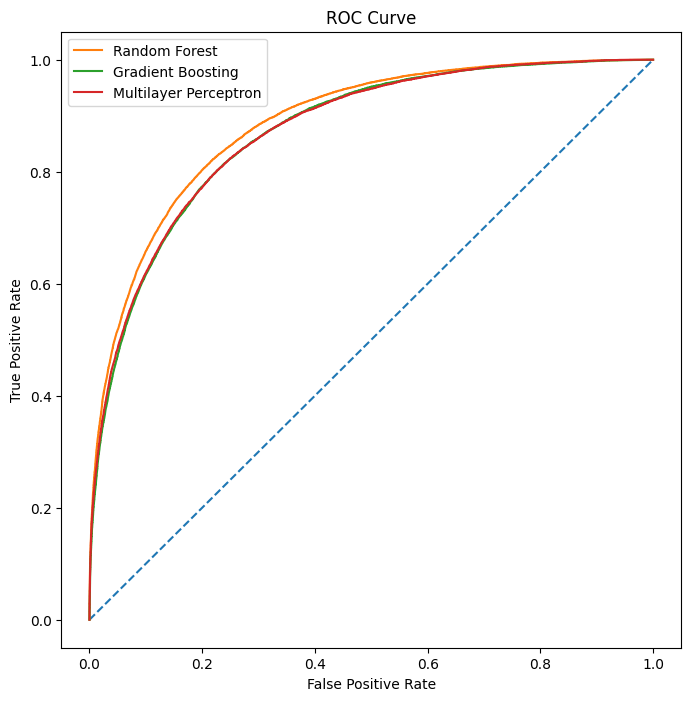

In [59]:
# ROC Curve
fig = plt.figure(figsize=(8, 8))
show_roc(models)

#### Precision-Recall Graph
The final evaluation technique is a plot which shows the relationship between the models' precision and recall.

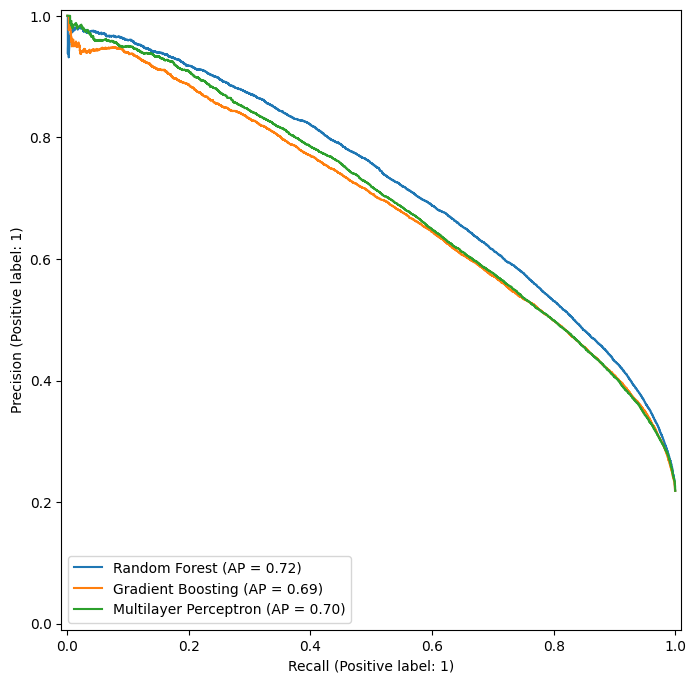

In [68]:
fig, ax = plt.subplots(1, 1, figsize=(8, 16))

PrecisionRecallDisplay.from_estimator(models[model_names[0]], features, targets, ax=ax, name=model_names[0])
PrecisionRecallDisplay.from_estimator(models[model_names[1]], features, targets, ax=ax, name=model_names[1])
PrecisionRecallDisplay.from_estimator(models[model_names[2]], features, targets, ax=ax, name=model_names[2])


### Conclusion
The problem implies that the metric recall is the most important metric. From the result table it is clear that recall varies between the models. Some models have a higher recall with lower accuracy and precision. It is important to balance the goal of the problem with how useful one wants the model to be. If there is a very strong desire to catch as many true positive values, which means it is going to rain tomorrow, the Linear Classification models can be used. If one wants a more versatile model, the tuned Decision Tree, Random Forest and neural network models will do a better job overall. The Decision Tree models shows great potential in the ROC Curve graph. The Random Forest has the second highest f1 score value and did well in the ROC curve plot, while the neural networks are generally good, but not great across all evaluation metrics. In particular the Keras Neural Network Model used in the confusion matrix fared well against the other models. While there is some subjectivity to which models are the best from these tests, some models have metrics which are average or bad across the board. These are Adaptive Boosting, the initial Decision Tree and Gradient Boosting.
Lastly it is reiterated that the Confusion matrices and ROC curve tests only use one model from the five available models where nested cross validation where used. This makes the models' performance in the tests more down to luck than it ideally should.


# Part B: Machine Learning in Production
This chapter of the notebook is dedicated to the new aspects of the development of machine learning models that is required for the 3rd mandatory assignment. The models which are used are all from their first fold. This is a limitation from the 2nd mandatory assignment. As such, only the first fold is used when testing.


In [70]:
# Start by creating test features and targets for fold 1 to match the model's fold.

# Duplicate dataset for use on threshold tuning.
dataset_AUS_temp = dataset_AUS.copy()

# Delete rows where target is missing:
dataset_AUS_temp.dropna(subset=['RainTomorrow'], inplace=True)

# Separate features and targets.
features = dataset_AUS_temp.drop(columns=['RainTomorrow'])
targets = dataset_AUS_temp['RainTomorrow'].map({'Yes' : 1, 'No' : 0})

# Ensure preprocessor pipeline returns pandas DataFrames.
preprocessor.set_output(transform='pandas')
# Use preprocessor pipeline on the duplicated dataset.
# Returns only features since target is simply mapped earlier.
features_processed = preprocessor.fit_transform(features, targets)

dates = pd.Series(dataset_AUS_temp['Date'])
unique_dates = pd.Series(dataset_AUS_temp['Date'].unique())
# Recreating outer loop
outer_test = TimeSeriesSplit(
    n_splits=5,
    gap=1
)
# Initialize dictionaries to manually access trainval and test from fold 1.
xTrainval_dict = {}
yTrainval_dict = {}
xTest_dict = {}
yTest_dict = {}
for fold, (trainCvIndices, testIndices) in enumerate(outer_test.split(unique_dates), 1):


        # Save trainval dates.
        outer_trainval_dates = unique_dates.iloc[trainCvIndices]

        # Checking which rows belong to Trainval.
        outer_trainval_rows = dates.isin(outer_trainval_dates)

        xTrainVal = features_processed.loc[outer_trainval_rows]
        yTrainVal = targets.loc[outer_trainval_rows]
        xTrainval_dict.update({fold : xTrainVal})
        yTrainval_dict.update({fold : yTrainVal})

        # Saves the test dates.
        outer_test_dates = unique_dates.iloc[testIndices]

        # Checking which rows belong to Testing.
        outer_test_rows = dates.isin(outer_test_dates)

        xTest = features_processed.loc[outer_test_rows]
        yTest = targets.loc[outer_test_rows]
        xTest_dict.update({fold : xTest})
        yTest_dict.update({fold : yTest})



# Trainval dataframes for fold 1.
featuresTrainVal_fold1 = xTrainval_dict[1]
targetsTrainVal_fold1 = yTrainval_dict[1]

# Testing dataframes for fold 1.
featuresTest_fold1 = xTest_dict[1]
targetsTest_fold1 = yTest_dict[1]



In [62]:
featuresTest_fold1.head()

,tmp_col_name_0_0,tmp_col_name_0_1,tmp_col_name_0_2,tmp_col_name_0_3,tmp_col_name_0_4,tmp_col_name_0_5,tmp_col_name_0_6,tmp_col_name_0_7,tmp_col_name_0_8,tmp_col_name_0_9,...,tmp_col_name_3_1,tmp_col_name_3_2,tmp_col_name_3_3,tmp_col_name_3_4,tmp_col_name_3_5,tmp_col_name_4_0,tmp_col_name_4_1,tmp_col_name_4_2,tmp_col_name_4_3,tmp_col_name_4_4
6634,-1.332929,-0.580617,-0.309374,-0.689795,0.197376,1.452263,0.034576,0.332891,-0.734865,-0.635708,...,9.238795e-01,9.238795e-01,-3.826834e-01,1.000000e+00,6.123234e-17,-0.866025,-0.5,-0.615285,-0.788305,2010.0
6635,-0.348724,-1.005339,1.205812,-0.497453,0.197376,0.911012,1.548419,0.569074,1.015706,-0.291322,...,9.238795e-01,-3.826834e-01,9.238795e-01,-2.449294e-16,1.000000e+00,-0.866025,-0.5,-0.628763,-0.777597,2010.0
6636,-1.082972,-1.868941,-0.066944,-0.449368,0.197376,0.756369,0.500374,-0.257568,1.121802,1.873393,...,3.826834e-01,-2.449294e-16,1.000000e+00,-7.071068e-01,7.071068e-01,-0.866025,-0.5,-0.642055,-0.766659,2010.0
6637,-0.848638,-1.783996,0.175485,-0.930223,0.197376,1.606906,1.781318,1.041441,0.538278,0.495847,...,-1.836970e-16,-1.000000e+00,-1.836970e-16,-1.000000e+00,-1.836970e-16,-0.866025,-0.5,-0.655156,-0.755493,2010.0
6638,-1.145461,-1.288487,-0.309374,-0.882137,0.197376,-0.944704,-0.431222,-1.438485,1.227897,0.200659,...,-3.826834e-01,-9.238795e-01,-3.826834e-01,-3.826834e-01,-9.238795e-01,-0.866025,-0.5,-0.668064,-0.744104,2010.0


### Threshold Tuning
Threshold tuning is done to the models when the dataset has an imbalanced distribution of target classes and if the classes have different penalties if chosen. To expand on the latter, it means that there is an imbalance in how much one accepts false positives and false negatives. It is more important to mitigate one of them then to have a balanced mix of both. Imbalance in target distribution and class penalties are both applicable to this dataset and problem(see 2nd assignment problem section). This makes threshold tuning highly relevant for this task.

The threshold value for this assignment refers to the probability of it raining tomorrow that is necessary for the model to actually predict that it is going to rain tomorrow. This is useful to tune because for two broad reasons. First, the user might want to change whether it is important to see if it is raining or not the next day. Secondly, there are far fewer days with rain in Australia than not, according to the dataset used. This means the models are trained on data which shows that it statistically is less likely to rain. This could lead to a bias when making new predictions which could be mitigated partially by changing the threshold.Finding a good threshold value can be done in two main ways. Either it can be done in a more manual way by looking at the precision-recall curve, or precision-recall prints, to see which threshold fits best to the different models. The other way is to use a scoring system to automatically decide which threshold best fits the model by guide of the score. Threshold tuning for this task is explained further in this assignment's report.

In [71]:
# Test Function used after tuning.
def test(model):
    train_predictions = model.predict(featuresTest_fold1)
    print(f'Test Accuracy: {accuracy_score(targetsTest_fold1, train_predictions,):.2f}')
    print(f'Test Precision: {precision_score(targetsTest_fold1, train_predictions):.2f}')
    print(f'Test Recall: {recall_score(targetsTest_fold1, train_predictions):.2f}')
    print(f'Test F1: {f1_score(targetsTest_fold1, train_predictions):.2f}')
    print(f'Test Fbeta: {fbeta_score(targetsTest_fold1, train_predictions, beta=beta)}:.2f')

In [72]:

beta = 1.5

rf_tuned = TunedThresholdClassifierCV(rf_grid, cv=5, scoring=make_scorer(fbeta_score, beta=beta))
rf_tuned.fit(featuresTrainVal_fold1, targetsTrainVal_fold1)
test(rf_tuned)

ValueError: 
All the 81 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
12 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\wilbn\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\_indexing.py", line 411, in _get_column_indices
    return [column_names.index(col) for col in selected_columns]
            ~~~~~~~~~~~~~~~~~~^^^^^
ValueError: list.index(x): x not in list

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "C:\Users\wilbn\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\model_selection\_validation.py", line 851, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File